All US counties: 3235
Map grid (CRS):  EPSG:4269
Nebraska counties: 93
       NAME  GEOID       ALAND
668  Seward  31159  1479997504
Bounds (west, south, east, north): [-97.368432  40.69794  -96.910495  41.046947]


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

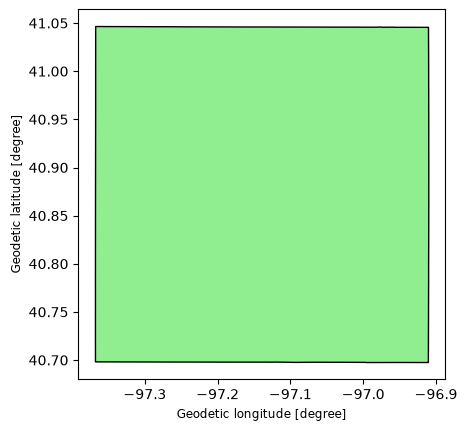

In [1]:
import geopandas as gpd

# 1. Load every US county border straight from the Census website (~11.6 MB)
url = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip"
counties = gpd.read_file(url)
print("All US counties:", len(counties))
print("Map grid (CRS): ", counties.crs)

# 2. Keep only Nebraska (state code 31)
nebraska = counties[counties["STATEFP"] == "31"]
print("Nebraska counties:", len(nebraska))

# 3. Pick Seward County
seward = nebraska[nebraska["NAME"] == "Seward"]
print(seward[["NAME", "GEOID", "ALAND"]])
print("Bounds (west, south, east, north):", seward.total_bounds)

# 4. Draw it
seward.plot(edgecolor="black", facecolor="lightgreen")

New CRS: EPSG:32614
Bounds in metres (left, bottom, right, top): [ 637149. 4506582.  676484. 4545979.]
Area (km²): 1491.3
Fully inside tile 14TPL? True


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

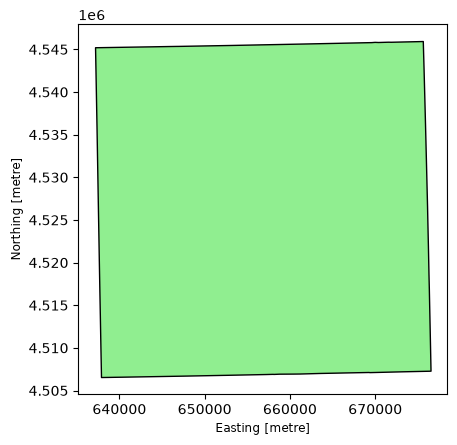

In [2]:
# 1. Convert the border from degrees (EPSG:4269) to the image's grid (EPSG:32614, metres)
seward_utm = seward.to_crs("EPSG:32614")
print("New CRS:", seward_utm.crs)
print("Bounds in metres (left, bottom, right, top):", seward_utm.total_bounds.round(0))

# 2. Check: area in km² should be close to ALAND (1,480 km²)
area_km2 = seward_utm.area.iloc[0] / 1_000_000
print("Area (km²):", round(area_km2, 1))

# 3. Check: is Seward fully inside our satellite tile?
#    Tile 14TPL bounds from notebook 01: left=600000, bottom=4490220, right=709800, top=4600020
left, bottom, right, top = seward_utm.total_bounds
inside = (left > 600000) and (right < 709800) and (bottom > 4490220) and (top < 4600020)
print("Fully inside tile 14TPL?", inside)

# 4. Draw it
seward_utm.plot(edgecolor="black", facecolor="lightgreen")

Image: S2B_14TPL_20220721_0_L2A
Array size (rows x cols): (3940, 3935)
Pixel size (m): 10.0 x 10.0
Share of blank pixels (outside border): 0.038
Valid area (km²): 1491.3
NDVI 1% / median / 99%: [0.24 0.78 0.92]


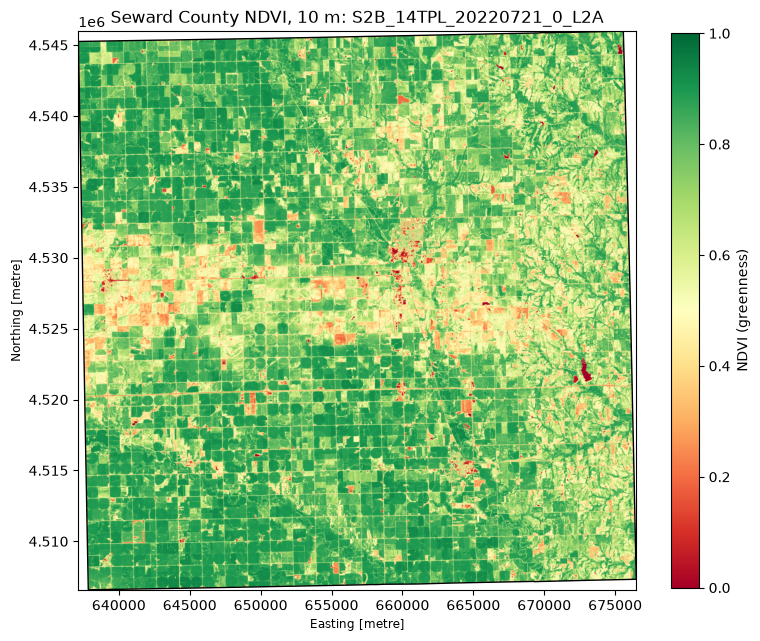

In [3]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from rasterio.mask import mask
from rasterio.plot import plotting_extent
from pystac_client import Client

# 1. Get the same image as before, directly by its ID (no need to search again)
catalog = Client.open("https://earth-search.aws.element84.com/v1")
item = catalog.get_collection("sentinel-2-l2a").get_item("S2B_14TPL_20220721_0_L2A")
print("Image:", item.id)

def read_county_reflectance(item, band_name, county):
    """Read one band, only inside the county border, at full resolution, as reflectance."""
    asset = item.assets[band_name]
    label = asset.extra_fields["raster:bands"][0]

    with rasterio.open(asset.href) as src:
        # Safety check: border and image must use the same map grid
        assert src.crs.to_epsg() == county.crs.to_epsg(), "CRS mismatch!"
        data, transform = mask(src, county.geometry, crop=True)   # the cookie cutter

    data = data[0].astype("float32")          # first (only) band, allow decimals
    data[data == label["nodata"]] = np.nan    # outside the county / no data, so blank

    # Earth Search already removed the offset when this flag is True (our earlier bug fix)
    offset = 0.0 if item.properties.get("earthsearch:boa_offset_applied") else label["offset"]
    return data * label["scale"] + offset, transform

red, transform = read_county_reflectance(item, "red", seward_utm)
nir, _         = read_county_reflectance(item, "nir", seward_utm)

ndvi = (nir - red) / (nir + red)

# Checks
print("Array size (rows x cols):", ndvi.shape)
print("Pixel size (m):", transform.a, "x", abs(transform.e))
print("Share of blank pixels (outside border):", round(float(np.isnan(ndvi).mean()), 3))
print("Valid area (km²):", round(float((~np.isnan(ndvi)).sum()) * 100 / 1e6, 1))
print("NDVI 1% / median / 99%:", np.nanpercentile(ndvi, [1, 50, 99]).round(2))

# Picture with the county border drawn on top
fig, ax = plt.subplots(figsize=(9, 9))
img = ax.imshow(ndvi, cmap="RdYlGn", vmin=0, vmax=1, extent=plotting_extent(ndvi, transform))
seward_utm.boundary.plot(ax=ax, color="black", linewidth=1)
plt.colorbar(img, ax=ax, label="NDVI (greenness)", shrink=0.8)
ax.set_title(f"Seward County NDVI, 10 m: {item.id}")
plt.show()

In [4]:
from rasterio.warp import reproject, Resampling

# 1. The partly cloudy image (10 days after our clear one)
cloudy = catalog.get_collection("sentinel-2-l2a").get_item("S2B_14TPL_20220731_0_L2A")
print("Image:", cloudy.id, "| cloud % over whole tile:", round(cloudy.properties["eo:cloud_cover"], 1))

# 2. NDVI for Seward on this date (reusing our function from Step 3)
red_c, transform_c = read_county_reflectance(cloudy, "red", seward_utm)
nir_c, _           = read_county_reflectance(cloudy, "nir", seward_utm)
ndvi_c = (nir_c - red_c) / (nir_c + red_c)

# 3. Read the SCL labels and stretch them from 20 m onto our 10 m grid
def read_scl_on_grid(item, shape, transform):
    scl = np.zeros(shape, dtype="uint8")          # empty 10 m grid to fill
    with rasterio.open(item.assets["scl"].href) as src:
        reproject(
            source=rasterio.band(src, 1), destination=scl,
            src_transform=src.transform, src_crs=src.crs,
            dst_transform=transform,     dst_crs=src.crs,   # same CRS, just a finer grid
            resampling=Resampling.nearest,                   # copy labels, never average
        )
    return scl

scl = read_scl_on_grid(cloudy, ndvi_c.shape, transform_c)

# 4. What share of Seward has each label?
names = {0: "no data", 1: "saturated/defective", 2: "dark area", 3: "cloud shadow",
         4: "vegetation", 5: "bare soil", 6: "water", 7: "unclassified",
         8: "cloud (medium)", 9: "cloud (high)", 10: "thin cirrus", 11: "snow"}
inside = ~np.isnan(ndvi_c)
codes, counts = np.unique(scl[inside], return_counts=True)
for code, n in zip(codes, counts):
    print(f"{code:>2}  {names[code]:<20} {n / inside.sum() * 100:5.1f}%")

Image: S2B_14TPL_20220731_0_L2A | cloud % over whole tile: 29.1
 2  dark area              0.0%
 3  cloud shadow          15.7%
 4  vegetation            63.4%
 5  bare soil              6.5%
 6  water                  0.0%
 7  unclassified           1.6%
 8  cloud (medium)         9.6%
 9  cloud (high)           3.0%
10  thin cirrus            0.3%


Share of Seward kept: 0.699
Median NDVI of cloud pixels:         0.31
Median NDVI 31 Jul, BEFORE masking:  0.71
Median NDVI 31 Jul, AFTER masking:   0.75
Median NDVI 21 Jul, same pixels:     0.77


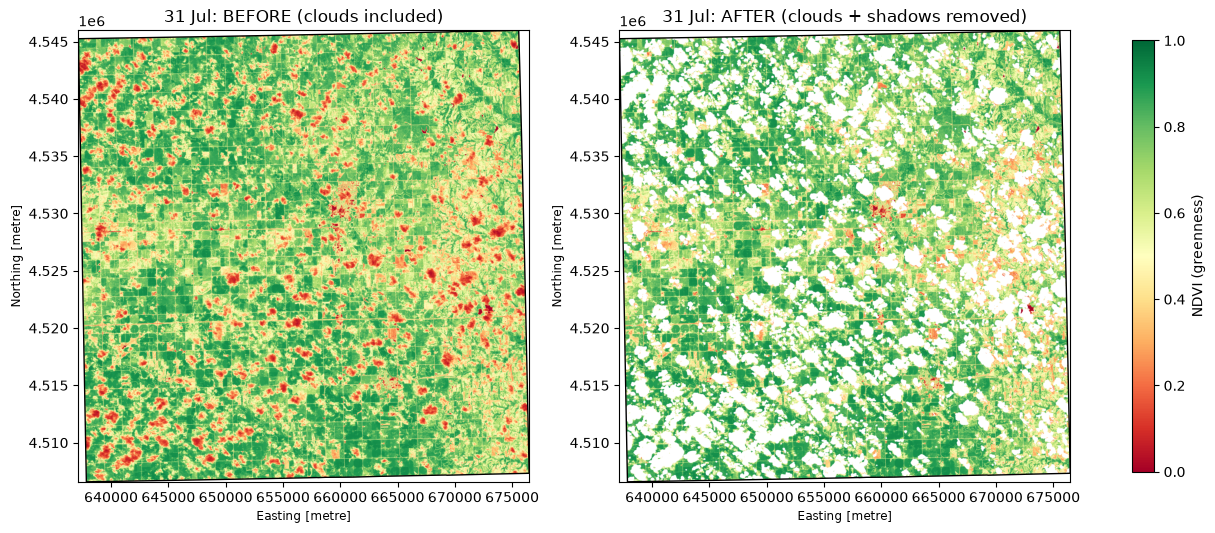

In [5]:
# 1. Keep only trustworthy pixels: vegetation (4), bare soil (5), water (6)
KEEP = [4, 5, 6]
good = np.isin(scl, KEEP)
ndvi_masked = np.where(good, ndvi_c, np.nan)      # everything else becomes blank

# 2. Numbers: what did masking change?
kept = (~np.isnan(ndvi_masked)).sum() / inside.sum()
cloudy_px = np.isin(scl, [8, 9, 10])
print("Share of Seward kept:", round(float(kept), 3))
print("Median NDVI of cloud pixels:        ", round(float(np.nanmedian(np.where(cloudy_px, ndvi_c, np.nan))), 2))
print("Median NDVI 31 Jul, BEFORE masking: ", round(float(np.nanmedian(ndvi_c)), 2))
print("Median NDVI 31 Jul, AFTER masking:  ", round(float(np.nanmedian(ndvi_masked)), 2))
print("Median NDVI 21 Jul, same pixels:    ", round(float(np.nanmedian(np.where(good, ndvi, np.nan))), 2))

# 3. Pictures side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
ext = plotting_extent(ndvi_c, transform_c)
for ax, arr, title in zip(axes, [ndvi_c, ndvi_masked],
                          ["31 Jul: BEFORE (clouds included)", "31 Jul: AFTER (clouds + shadows removed)"]):
    im = ax.imshow(arr, cmap="RdYlGn", vmin=0, vmax=1, extent=ext)
    seward_utm.boundary.plot(ax=ax, color="black", linewidth=1)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.7, label="NDVI (greenness)")
plt.show()

In [6]:
from pathlib import Path

# 1. Find the project folder (the one containing pyproject.toml), wherever the notebook runs from
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
out_path = root / "results" / "seward_ndvi_20220731_masked.tif"

# 2. Describe the file: size, number type, map grid, position, blank value, compression
profile = {
    "driver": "GTiff",
    "height": ndvi_masked.shape[0],
    "width": ndvi_masked.shape[1],
    "count": 1,                      # one layer (NDVI)
    "dtype": "float32",              # decimal numbers
    "crs": "EPSG:32614",             # map grid
    "transform": transform_c,        # position + pixel size
    "nodata": np.nan,                # blank = NaN
    "compress": "deflate",           # shrink the file without losing data
    "predictor": 3,                  # helps compress decimal numbers better
    "tiled": True, "blockxsize": 512, "blockysize": 512,   # store in 512x512 blocks (fast to read parts)
}

# 3. Write the file + attach provenance notes
with rasterio.open(out_path, "w", **profile) as dst:
    dst.write(ndvi_masked.astype("float32"), 1)
    dst.update_tags(
        source_item=cloudy.id,
        index="NDVI",
        mask="SCL keep 4,5,6 (vegetation, bare soil, water)",
        county="Seward, NE (GEOID 31159)",
    )
print("Saved:", out_path)

# 4. Re-open the saved file and check it is correct
with rasterio.open(out_path) as check:
    saved = check.read(1)
    print("CRS:        ", check.crs)
    print("Pixel size: ", check.res)
    print("Bounds:     ", check.bounds)
    print("Notes:      ", check.tags())
    print("Median NDVI:", round(float(np.nanmedian(saved)), 2), "(should be 0.75)")
print("File size (MB):", round(out_path.stat().st_size / 1e6, 1))

Saved: /Users/iffat180/Desktop/AgroScope/results/seward_ndvi_20220731_masked.tif
CRS:         EPSG:32614
Pixel size:  (10.0, 10.0)
Bounds:      BoundingBox(left=637140.0, bottom=4506580.0, right=676490.0, top=4545980.0)
Notes:       {'county': 'Seward, NE (GEOID 31159)', 'index': 'NDVI', 'mask': 'SCL keep 4,5,6 (vegetation, bare soil, water)', 'source_item': 'S2B_14TPL_20220731_0_L2A', 'AREA_OR_POINT': 'Area'}
Median NDVI: 0.75 (should be 0.75)
File size (MB): 32.9
